# Практическое занятие №5-6
## Практическая работа: «Знакомство с алгоритмом k-ближайших соседей (kNN)». Переобучение и регуляризация

**Дисциплина:** «Алгоритмы машинного обучения для решения прикладных задач»

**Цель работы:** изучить алгоритм k-ближайших соседей на наборе данных «Ирисы Фишера», а затем применить его
для определения качества красного вина (набор `winequality-red.csv`), исследовать явление переобучения
и способы его ограничения (выбор числа соседей, масштабирование признаков, кросс-валидация).

## Часть 1. kNN на наборе данных «Ирисы Фишера» (разбор примера)

In [1]:
# Импорт необходимых библиотек
import warnings
warnings.filterwarnings('ignore')

import itertools
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions

from sklearn import datasets
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

### Изучение набора данных
Набор состоит из 150 образцов трёх видов ирисов (setosa, versicolor, virginica), по 4 признака: длина и ширина чашелистика и лепестка (см).

In [2]:
dataset = datasets.load_iris()
df = pd.DataFrame(data=np.c_[dataset['data'], dataset['target']],
                  columns=dataset['feature_names'] + ['target'])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB


In [4]:
dict(zip(dataset.target_names, df['target'].unique()))

{np.str_('setosa'): np.float64(0.0),
 np.str_('versicolor'): np.float64(1.0),
 np.str_('virginica'): np.float64(2.0)}

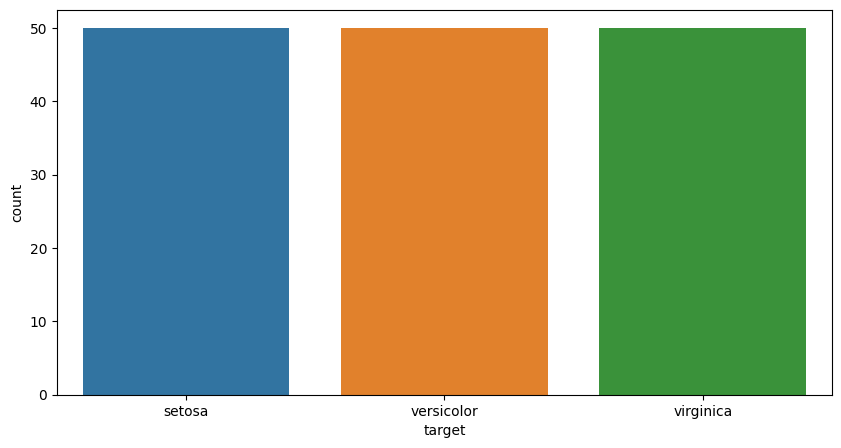

In [5]:
temp_df = df.copy()
temp_df['target'] = temp_df['target'].map(dict(zip(temp_df['target'].unique(), dataset.target_names)))
sns.countplot(x='target', hue='target', data=temp_df);

Классы идеально сбалансированы — по 50 объектов каждого вида.

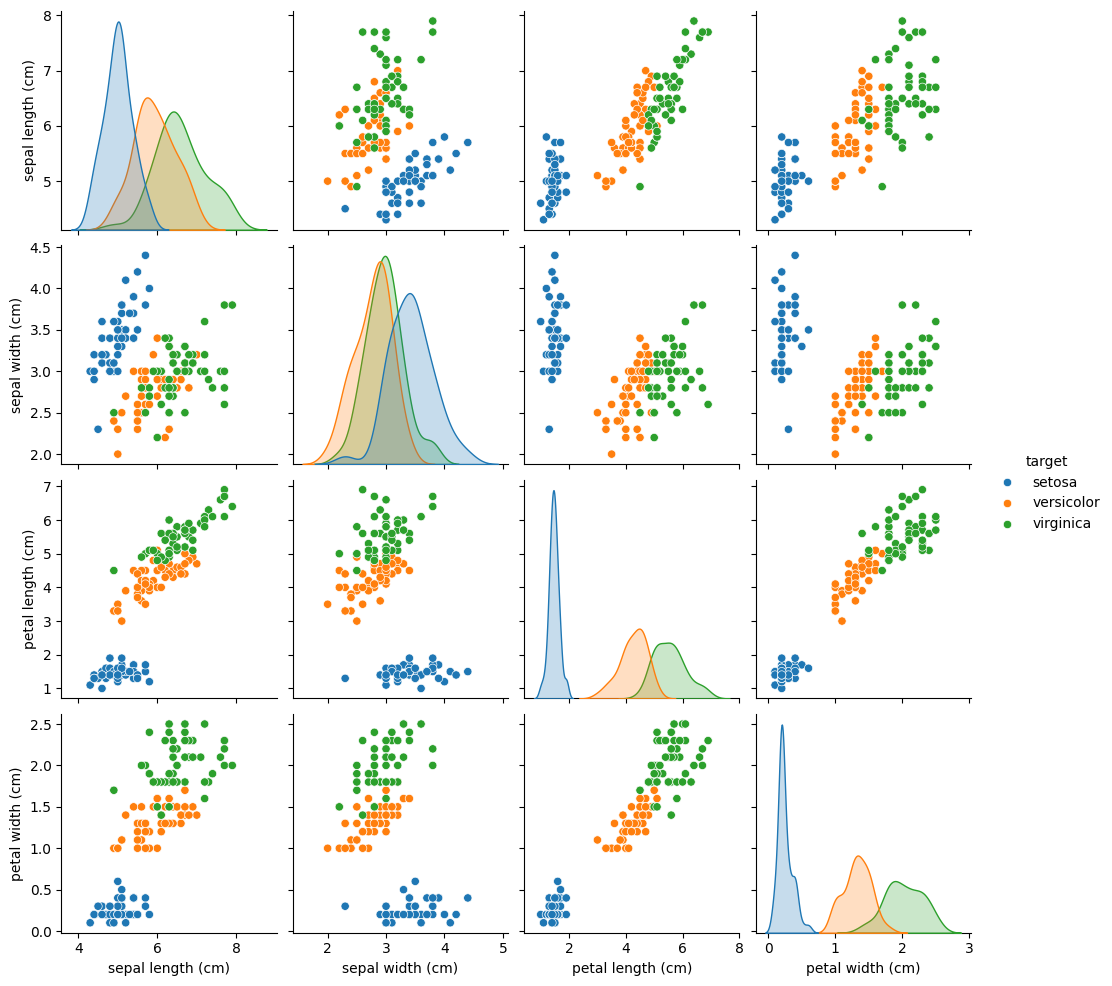

In [6]:
sns.pairplot(temp_df, hue='target');

По попарным диаграммам видно, что признаки лепестка (petal length / width) разделяют классы гораздо лучше, чем признаки чашелистика. Setosa линейно отделима от остальных видов.

In [7]:
# Вспомогательная функция для вывода матрицы ошибок
def display_confusion_matrix(matrix, labels=None, title="Confusion Matrix",
                             xlabel="Predicted", ylabel="Actual", figsize=None,
                             cmap="Blues", vmin=None, vmax=None):
    """Отобразить матрицу ошибок с помощью matplotlib."""
    if labels is None:
        labels = [""] * len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = matrix.max()
    t_hold = (vmax - vmin) / 2.
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax)
    for row, col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row, col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

### Модель 1 (длина и ширина чашелистика)

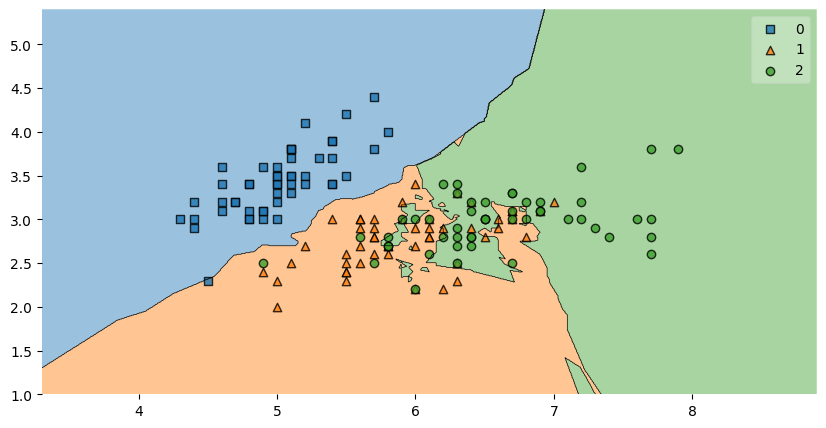

In [8]:
X = df[['sepal length (cm)', 'sepal width (cm)']]
y_true = df['target']
model_1 = KNeighborsClassifier()
model_1.fit(X, y_true)
plot_decision_regions(X.values, y_true.values.astype(int), model_1);

[[49  1  0]
 [ 0 38 12]
 [ 0 12 38]]
accuracy = 0.8333333333333334


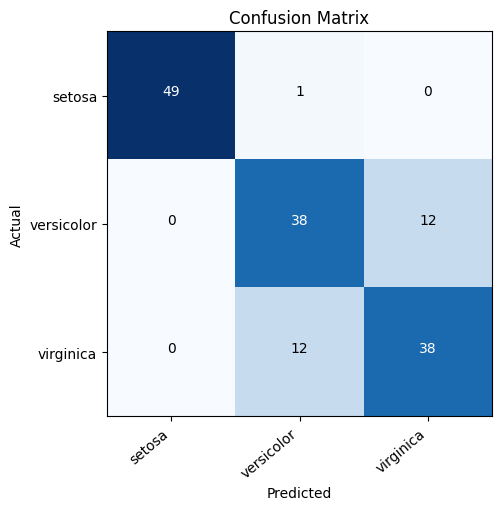

In [9]:
y_hat = model_1.predict(X)
labels = df["target"].unique()
matrix = confusion_matrix(y_true, y_hat, labels=labels)
print(matrix)
print('accuracy =', accuracy_score(y_true, y_hat))
display_confusion_matrix(matrix, dataset.target_names)

### Модель 2 (длина и ширина лепестка)

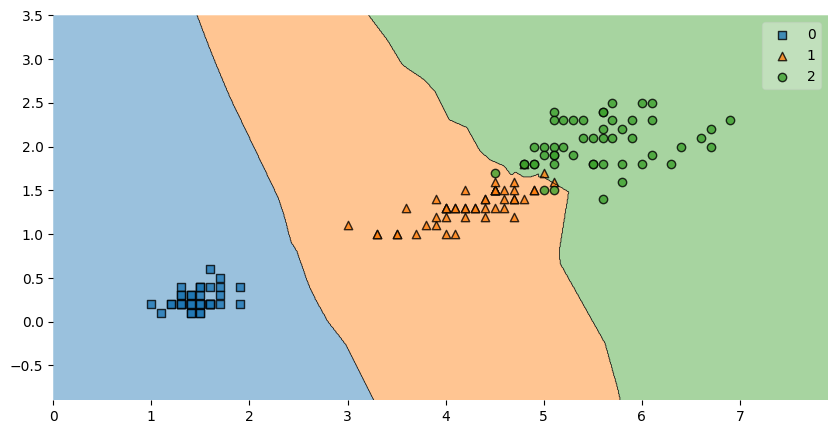

In [10]:
X = df[['petal length (cm)', 'petal width (cm)']]
model_2 = KNeighborsClassifier()
model_2.fit(X, y_true)
plot_decision_regions(X.values, y_true.values.astype(int), model_2);

[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]
accuracy = 0.96


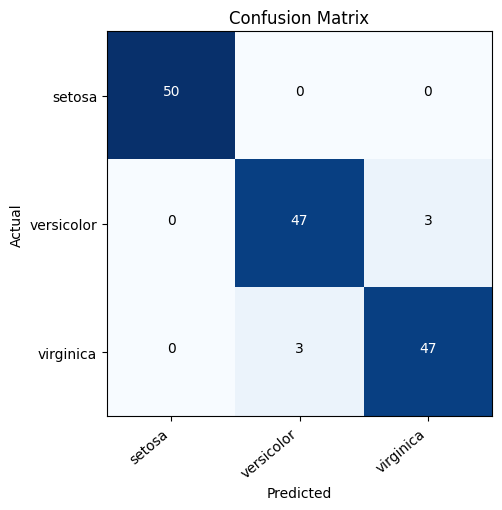

In [11]:
y_hat = model_2.predict(X)
matrix = confusion_matrix(y_true, y_hat, labels=labels)
print(matrix)
print('accuracy =', accuracy_score(y_true, y_hat))
display_confusion_matrix(matrix, dataset.target_names)

### Модель 3 (все признаки)

[[50  0  0]
 [ 0 47  3]
 [ 0  2 48]]
accuracy = 0.9666666666666667


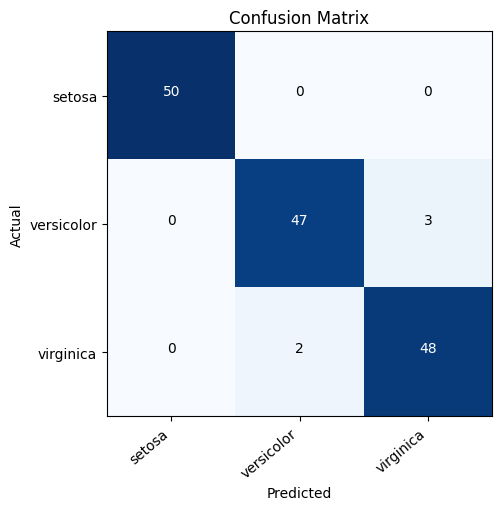

In [12]:
X = df.drop(['target'], axis=1)
model_3 = KNeighborsClassifier()
model_3.fit(X, y_true)
y_hat = model_3.predict(X)
matrix = confusion_matrix(y_true, y_hat, labels=labels)
print(matrix)
print('accuracy =', accuracy_score(y_true, y_hat))
display_confusion_matrix(matrix, dataset.target_names)

Модель на всех признаках ошибается реже всех. Однако до сих пор модели обучались и оценивались на одних и тех же данных — такая оценка завышена. Разделим выборку на обучающую и тестовую.

### Модель на разделённом наборе данных

In [13]:
X = df.drop(['target'], axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3,
                                                    random_state=RANDOM_STATE)
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
preds = knn.predict(X_test)
print(classification_report(y_test, preds, target_names=dataset.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]


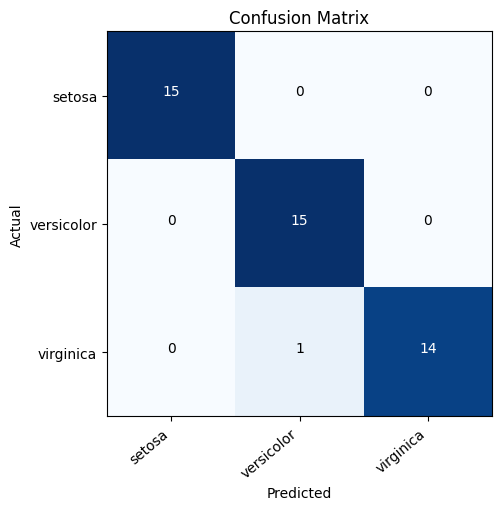

In [14]:
matrix = confusion_matrix(y_test, preds, labels=y.unique())
print(matrix)
display_confusion_matrix(matrix, dataset.target_names)

In [15]:
iris_test_acc = accuracy_score(y_test, preds); iris_test_acc

0.9777777777777777

## Часть 2. Задание: определение качества красного вина методом kNN

**Задание.** С помощью метода kNN определить качество красного вина. Использовать датасет `winequality-red.csv` (папка `data`).
Разделить набор данных на обучающий и тестовый, обучить модель на обучающем наборе, построить матрицу путаницы, сделать выводы.

Набор данных Wine Quality (UCI, P. Cortez et al., 2009): 1599 образцов красного вина «Vinho Verde», 11 физико-химических
признаков и целевая переменная `quality` — экспертная оценка от 0 до 10.

### 2.1. Загрузка и изучение данных

In [16]:
wine = pd.read_csv('data/winequality-red.csv')
print(wine.shape)
wine.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [17]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [18]:
wine.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


In [19]:
print('Пропусков:', wine.isna().sum().sum(), '| Дубликатов:', wine.duplicated().sum())
quality_counts = wine['quality'].value_counts().sort_index()
quality_counts

Пропусков: 0 | Дубликатов: 240


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

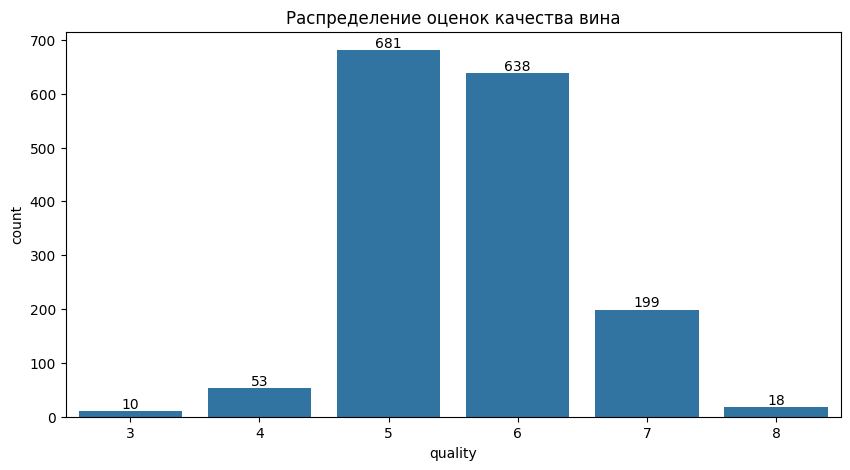

In [20]:
ax = sns.countplot(x='quality', data=wine, color='tab:blue')
ax.bar_label(ax.containers[0])
plt.title('Распределение оценок качества вина');

Классы **сильно несбалансированы**: почти 82 % вин имеют оценку 5 или 6, а оценок 3 и 8 — единицы (10 и 18 образцов).
Оценок 0–2 и 9–10 в данных нет вовсе. Это главная сложность задачи: метрика accuracy будет определяться
в основном качеством распознавания классов 5 и 6.

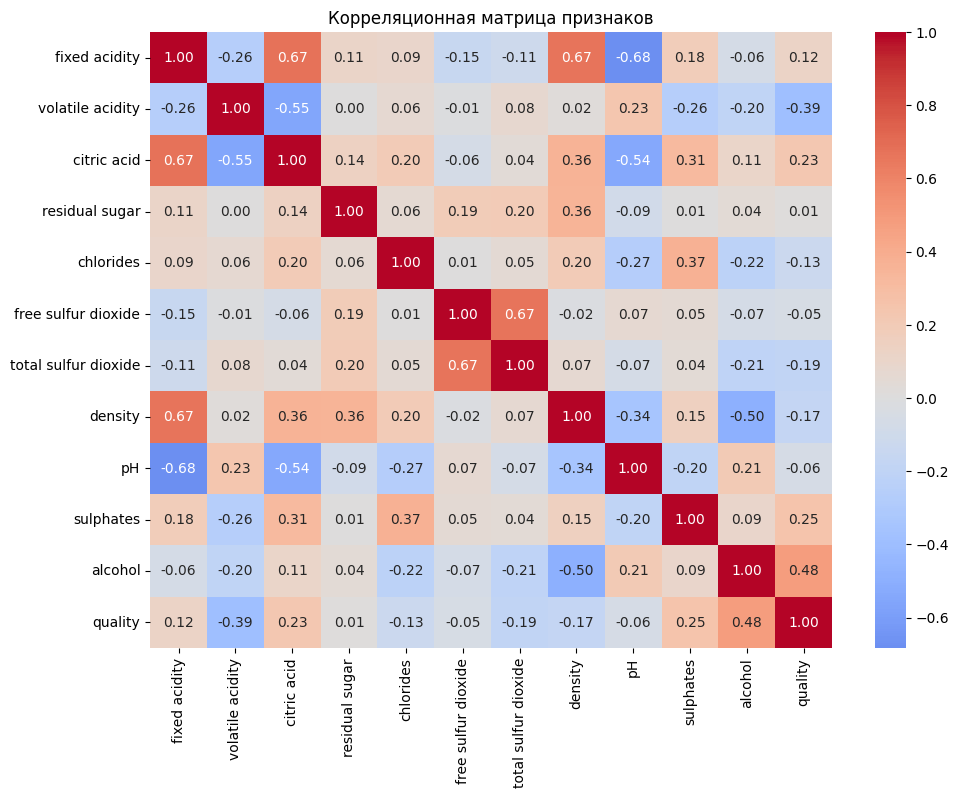

In [21]:
plt.figure(figsize=(11, 8))
sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица признаков');

In [22]:
wine.corr()['quality'].drop('quality').sort_values()

volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
Name: quality, dtype: float64

Сильнее всего с качеством связаны: содержание алкоголя (+0.48), летучая кислотность (−0.39), сульфаты (+0.25) и лимонная кислота (+0.23).

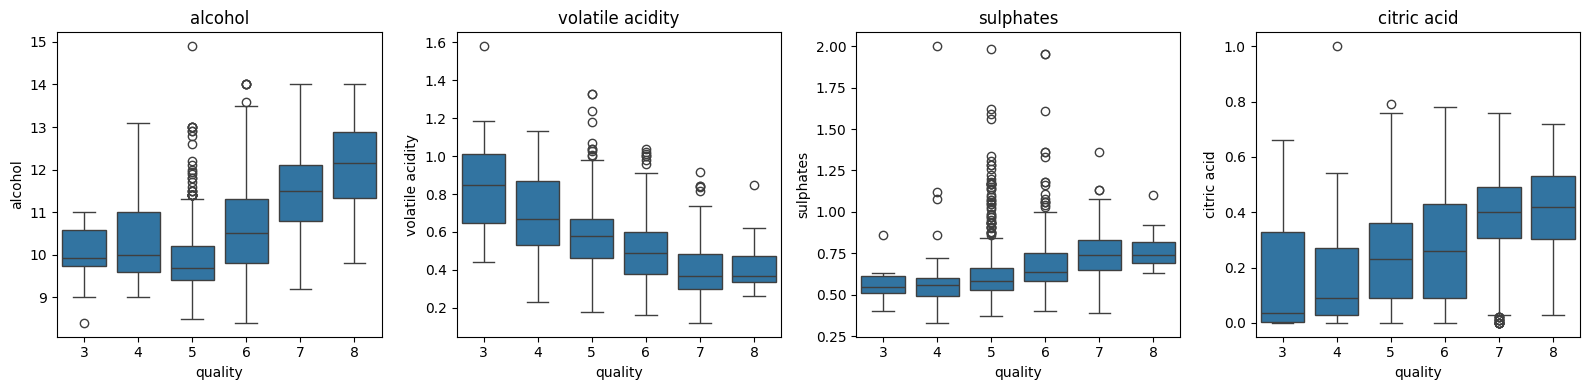

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['alcohol', 'volatile acidity', 'sulphates', 'citric acid']):
    sns.boxplot(x='quality', y=col, data=wine, ax=ax, color='tab:blue')
    ax.set_title(col)
plt.tight_layout()

Признаки имеют совершенно разные масштабы (например, `total sulfur dioxide` до 289, а `density` ≈ 1.0 с разбросом 0.002). Для kNN, который опирается на евклидово расстояние, это критично — без масштабирования расстояние будут определять только «крупные» признаки.

### 2.2. Разделение на обучающую и тестовую выборки

In [24]:
X = wine.drop('quality', axis=1)
y = wine['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y,
                                                    random_state=RANDOM_STATE)
print('train:', X_train.shape, ' test:', X_test.shape)
quality_labels = sorted(y.unique())

train: (1199, 11)  test: (400, 11)


### 2.3. Базовая модель kNN (k = 5, без масштабирования)

In [25]:
knn_raw = KNeighborsClassifier()           # k = 5 по умолчанию
knn_raw.fit(X_train, y_train)
pred_raw = knn_raw.predict(X_test)
print(f'train accuracy = {knn_raw.score(X_train, y_train):.3f}')
print(f'test  accuracy = {accuracy_score(y_test, pred_raw):.3f}')
print(classification_report(y_test, pred_raw, zero_division=0))

train accuracy = 0.641
test  accuracy = 0.500
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        13
           5       0.55      0.67      0.61       170
           6       0.47      0.50      0.49       160
           7       0.24      0.12      0.16        50
           8       0.00      0.00      0.00         5

    accuracy                           0.50       400
   macro avg       0.21      0.22      0.21       400
weighted avg       0.45      0.50      0.47       400



### 2.4. kNN с масштабированием признаков (StandardScaler)

In [26]:
knn_scaled = Pipeline([('scaler', StandardScaler()),
                       ('knn', KNeighborsClassifier())])
knn_scaled.fit(X_train, y_train)
pred_scaled = knn_scaled.predict(X_test)
print(f'train accuracy = {knn_scaled.score(X_train, y_train):.3f}')
print(f'test  accuracy = {accuracy_score(y_test, pred_scaled):.3f}')
print(classification_report(y_test, pred_scaled, zero_division=0))

train accuracy = 0.711
test  accuracy = 0.603
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        13
           5       0.66      0.72      0.69       170
           6       0.57      0.61      0.59       160
           7       0.51      0.40      0.45        50
           8       0.00      0.00      0.00         5

    accuracy                           0.60       400
   macro avg       0.29      0.29      0.29       400
weighted avg       0.57      0.60      0.59       400



Масштабирование признаков заметно повышает качество — теперь все признаки вносят сопоставимый вклад в расстояние.

### 2.5. Переобучение и выбор числа соседей k

Число соседей *k* — это параметр «регуляризации» kNN:
* при **k = 1** модель запоминает обучающую выборку (accuracy на train = 1.0) — это **переобучение**, граница решений очень «рваная»;
* при **большом k** модель усредняет слишком много соседей и скатывается к предсказанию самого частого класса — **недообучение**.

Построим кривые качества на обучающей выборке, на кросс-валидации (5 фолдов) и на тесте.

Лучшее k по кросс-валидации (uniform): 1 cv acc = 0.607


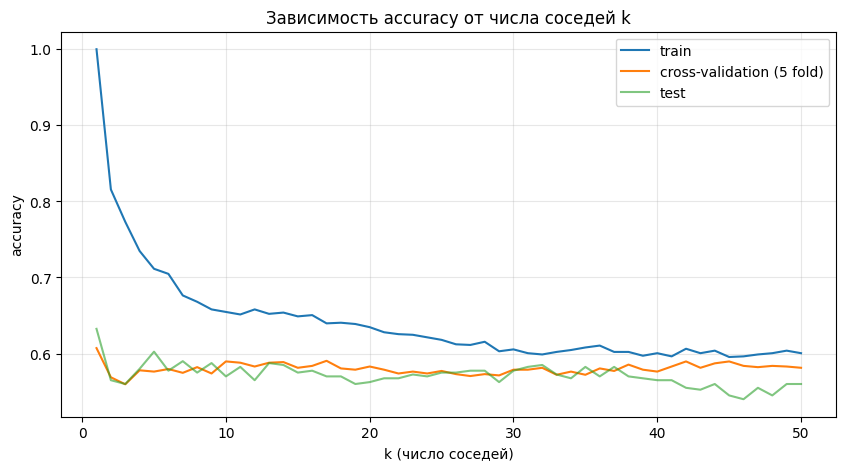

In [27]:
ks = range(1, 51)
train_acc, cv_acc, test_acc = [], [], []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for k in ks:
    model = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=k))])
    cv_acc.append(cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy').mean())
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.plot(ks, train_acc, label='train')
plt.plot(ks, cv_acc, label='cross-validation (5 fold)')
plt.plot(ks, test_acc, label='test', alpha=0.6)
plt.xlabel('k (число соседей)'); plt.ylabel('accuracy')
plt.title('Зависимость accuracy от числа соседей k'); plt.legend(); plt.grid(alpha=0.3);
best_k_uniform = list(ks)[int(np.argmax(cv_acc))]
print('Лучшее k по кросс-валидации (uniform):', best_k_uniform, f'cv acc = {max(cv_acc):.3f}')

Accuracy на обучающей выборке монотонно падает от 1.0 при k = 1 до ≈ 0.60 при k = 50, тогда как на кросс-валидации и тесте
она почти не меняется (≈ 0.57–0.61). Огромный разрыв между train и CV при малых k — наглядная мера переобучения: модель запоминает
обучающие объекты, но не обобщает. Небольшой пик CV при k = 1 объясняется тем, что в данных много одинаковых вин (240 дубликатов, 15 %),
и ближайший сосед часто оказывается «двойником» объекта. При равных весах соседей увеличение k почти не даёт выигрыша —
поэтому далее подберём ещё и способ взвешивания соседей и метрику расстояния.

### 2.6. Подбор гиперпараметров (GridSearchCV)

In [28]:
param_grid = {
    'knn__n_neighbors': list(range(1, 41)),
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],                      # 1 — манхэттенское, 2 — евклидово расстояние
}
grid = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
                    param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)
print('Лучшие параметры:', grid.best_params_)
print(f'CV accuracy = {grid.best_score_:.3f}')

Лучшие параметры: {'knn__n_neighbors': 23, 'knn__p': 1, 'knn__weights': 'distance'}
CV accuracy = 0.674


In [29]:
best_knn = grid.best_estimator_
pred_best = best_knn.predict(X_test)
print(f'test accuracy = {accuracy_score(y_test, pred_best):.3f}')
print(f'test macro F1 = {f1_score(y_test, pred_best, average="macro"):.3f}')
print(classification_report(y_test, pred_best, zero_division=0))

test accuracy = 0.657
test macro F1 = 0.376
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        13
           5       0.73      0.74      0.73       170
           6       0.59      0.71      0.64       160
           7       0.66      0.46      0.54        50
           8       1.00      0.20      0.33         5

    accuracy                           0.66       400
   macro avg       0.50      0.35      0.38       400
weighted avg       0.64      0.66      0.64       400



### 2.7. Матрица путаницы

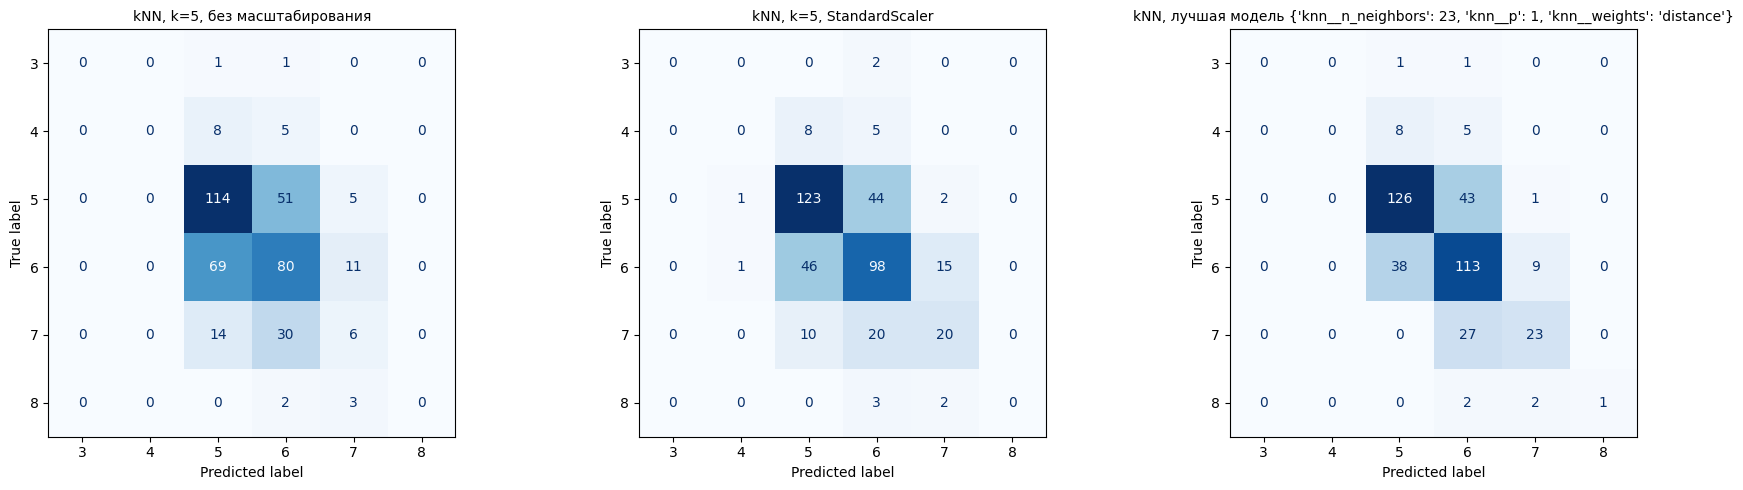

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, pred) in zip(axes, [('kNN, k=5, без масштабирования', pred_raw),
                                     ('kNN, k=5, StandardScaler', pred_scaled),
                                     (f'kNN, лучшая модель {grid.best_params_}', pred_best)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=quality_labels, ax=ax,
                                            cmap='Blues', colorbar=False)
    ax.set_title(title, fontsize=10)
plt.tight_layout()

In [31]:
cm = confusion_matrix(y_test, pred_best, labels=quality_labels)
off_by_one = sum(cm[i, j] for i in range(len(cm)) for j in range(len(cm)) if abs(i - j) == 1)
off_more = sum(cm[i, j] for i in range(len(cm)) for j in range(len(cm)) if abs(i - j) > 1)
print(f'Верно: {np.trace(cm)} из {cm.sum()}; ошибка на 1 балл: {off_by_one}; ошибка более чем на 1 балл: {off_more}')

Верно: 263 из 400; ошибка на 1 балл: 127; ошибка более чем на 1 балл: 10


### 2.8. Дополнительно: бинарная постановка («хорошее» вино, quality ≥ 7)

На практике часто важнее отличить хорошее вино от остальных. Сведём задачу к бинарной классификации.

Доля хороших вин: 0.135


Лучшие параметры: {'knn__n_neighbors': 10, 'knn__p': 2, 'knn__weights': 'distance'}
              precision    recall  f1-score   support

     обычное       0.92      0.97      0.94       345
     хорошее       0.68      0.47      0.56        55

    accuracy                           0.90       400
   macro avg       0.80      0.72      0.75       400
weighted avg       0.89      0.90      0.89       400



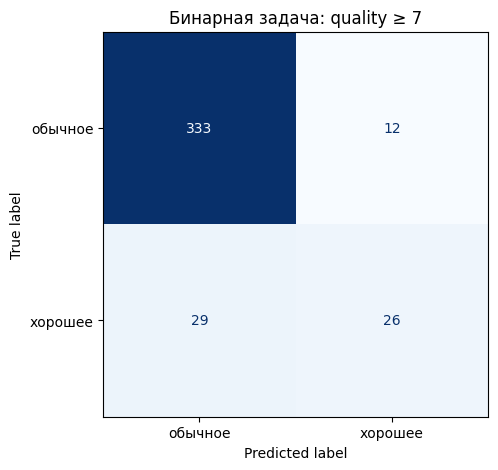

In [32]:
y_bin_train = (y_train >= 7).astype(int)
y_bin_test = (y_test >= 7).astype(int)
print('Доля хороших вин:', round(y_bin_train.mean(), 3))
grid_bin = GridSearchCV(Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
                        param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid_bin.fit(X_train, y_bin_train)
pred_bin = grid_bin.predict(X_test)
print('Лучшие параметры:', grid_bin.best_params_)
print(classification_report(y_bin_test, pred_bin, target_names=['обычное', 'хорошее']))
ConfusionMatrixDisplay.from_predictions(y_bin_test, pred_bin, display_labels=['обычное', 'хорошее'],
                                        cmap='Blues', colorbar=False)
plt.title('Бинарная задача: quality ≥ 7');

### 2.9. Сводная таблица результатов

In [33]:
summary = pd.DataFrame({
    'Модель': ['kNN k=5 без масштабирования', 'kNN k=5 + StandardScaler',
               f'kNN подобранная ({grid.best_params_})', 'Бинарная: quality ≥ 7'],
    'Train accuracy': [knn_raw.score(X_train, y_train), knn_scaled.score(X_train, y_train),
                       best_knn.score(X_train, y_train), accuracy_score(y_bin_train, grid_bin.predict(X_train))],
    'Test accuracy': [accuracy_score(y_test, pred_raw), accuracy_score(y_test, pred_scaled),
                      accuracy_score(y_test, pred_best), accuracy_score(y_bin_test, pred_bin)],
    'Test macro F1': [f1_score(y_test, pred_raw, average='macro'), f1_score(y_test, pred_scaled, average='macro'),
                      f1_score(y_test, pred_best, average='macro'), f1_score(y_bin_test, pred_bin, average='macro')],
}).round(3)
summary.to_csv('results_pr5_6.csv', index=False)
summary

,Модель,Train accuracy,Test accuracy,Test macro F1
0,kNN k=5 без масштабирования,0.641,0.500,0.209
1,kNN k=5 + StandardScaler,0.711,0.602,0.288
2,"kNN подобранная ({'knn__n_neighbors': 23, 'knn...",1.000,0.658,0.376
3,Бинарная: quality ≥ 7,1.000,0.898,0.751


## Выводы

1. На наборе «Ирисы Фишера» kNN показывает очень высокое качество: признаки лепестка почти идеально разделяют виды,
   а модель на всех признаках на отложенной тестовой выборке ошибается лишь на единичных объектах.
2. Задача определения качества красного вина значительно сложнее: классы сильно несбалансированы (82.5 % вин имеют оценку 5–6,
   оценок 3 и 8 — всего 10 и 18), а физико-химические признаки лишь частично объясняют субъективную экспертную оценку.
3. **Масштабирование признаков обязательно для kNN**: без него accuracy на тесте 0.50, со StandardScaler — 0.60.
   Без масштабирования расстояние определяется признаками с большим диапазоном (`total sulfur dioxide`, `free sulfur dioxide`).
4. Число соседей *k* управляет балансом «переобучение / недообучение»: при k = 1 accuracy на обучающей выборке равна 1.0,
   а на кросс-валидации ≈ 0.61 — классическое переобучение. Подбор гиперпараметров по кросс-валидации дал k = 23,
   манхэттенскую метрику (p = 1) и взвешивание соседей по расстоянию: accuracy на тесте **0.66**, macro F1 = 0.38.
   При взвешивании по расстоянию accuracy на train равна 1.0 (объект — сам себе ближайший сосед), поэтому качество
   оценивается только на кросс-валидации и тестовой выборке.
5. Матрица путаницы показывает, что из 137 ошибок лучшей модели 127 — это ошибки **на один балл** (5↔6, 6↔7);
   редкие классы 3 и 4 модель не распознаёт вовсе, класс 8 — лишь в одном случае из пяти.
6. В бинарной постановке («хорошее» вино, quality ≥ 7) kNN даёт accuracy 0.90 и F1 по классу «хорошее» 0.56
   (precision 0.68, recall 0.47); полнота ограничена дисбалансом классов. Для улучшения можно применять балансировку классов,
   отбор признаков или другие алгоритмы (случайный лес, градиентный бустинг).